# Explore How Well Convex Hulls Represent Extreme Cases

## Import Libraries

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor

from scipy.spatial import ConvexHull
from sklearn.datasets import make_regression

# Print package versions for reproducibility
print('Versions of imported libraries:')
print(f"  matplotlib: {mpl.__version__}")
print(f"  numpy: {np.__version__}")
print(f"  pandas: {pd.__version__}")
print(f"  seaborn: {sns.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  xgboost: {xgboost.__version__}")

Versions of imported libraries:
  matplotlib: 3.7.1
  numpy: 1.24.3
  pandas: 1.5.3
  seaborn: 0.12.2
  scikit-learn: 1.3.0
  xgboost: 2.0.2


## Linear Function

In [ ]:
X, y = make_regression(n_samples = 1000, n_features = 2, noise = 10, random_state = 42)

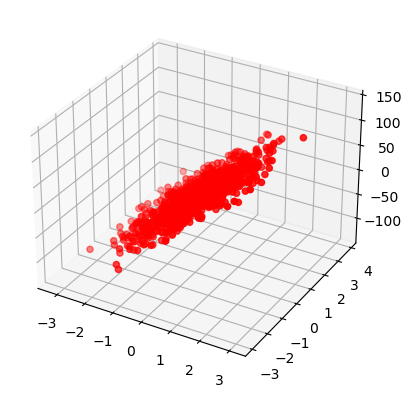

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
# ax.plot_surface(X[0], X[1], y, cmap='viridis')
ax.scatter(X[:, 0], X[:, 1], y, c='r', marker='o')
plt.show()

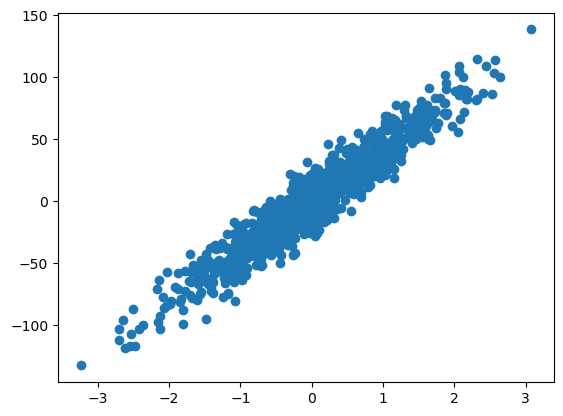

In [ ]:
plt.scatter(X[:, 0], y)
plt.show()

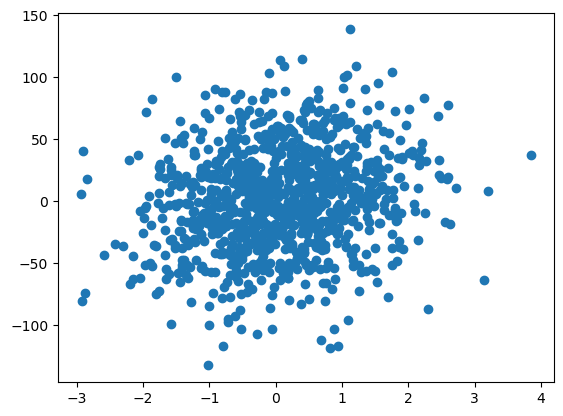

In [ ]:
plt.scatter(X[:, 1], y)
plt.show()

### Correlation Coefficient

In [ ]:
correlation_matrix = np.corrcoef(X[:, 0], y)
correlation_coef = correlation_matrix[0, 1]
print(correlation_coef)

0.9566817624279236


## Non-Linear Function

In [20]:
x = np.linspace(-np.pi, np.pi, 100)
y = np.linspace(-np.pi, np.pi, 100)
X, Y = np.meshgrid(x, y)
R = np.sqrt(X**2 + Y**2)
mask = R <= np.pi

Z = 10*np.sin(R)
Z[~mask] = np.nan

### Function Visualisation

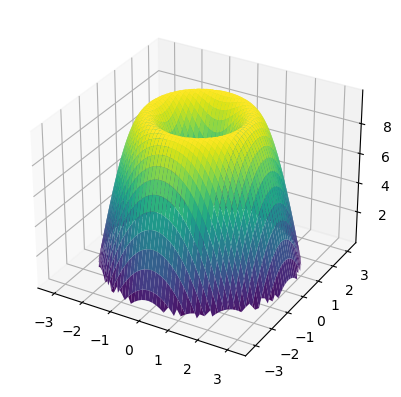

In [21]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis')
plt.show()

### Data Sampling

In [36]:
num_samples = 1500
X = np.random.uniform(-np.pi, np.pi, num_samples)
Y = np.random.uniform(-np.pi, np.pi, num_samples)
mask = X**2 + Y**2 <= np.pi**2
X_circle = X[mask]
Y_circle = Y[mask]
Z = 10*np.sin(np.sqrt(X_circle**2 + Y_circle**2))
data = np.column_stack((X_circle, Y_circle))

### Data Splitting

In [37]:
X_train, X_test, y_train, y_test = train_test_split(data, Z, test_size=0.3, random_state=42)

### Training Set Visualisation

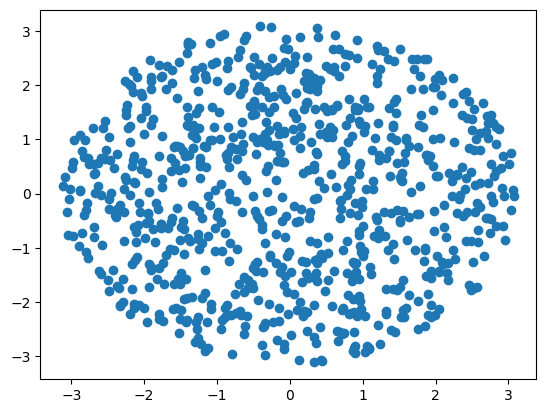

In [38]:
plt.scatter(X_train[:,0],X_train[:,1])
plt.show()

### Convex Hull Computation & Visualisation

In [39]:
hull = ConvexHull(X_train)
X_hull = X_train[hull.vertices]
y_hull = y_train[hull.vertices]

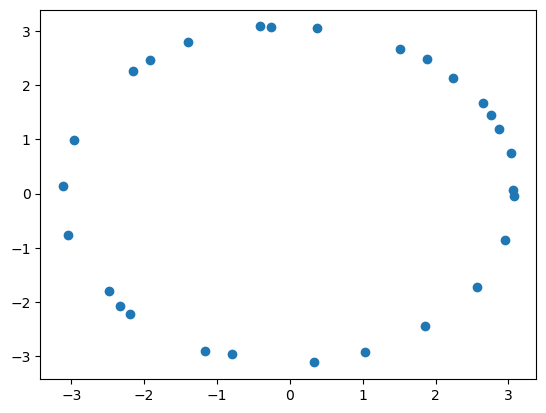

In [40]:
plt.scatter(X_hull[:,0],X_hull[:,1])
plt.show()

In [41]:
# Make sure that all points from y_hull is close to 0
y_hull

array([0.20491631, 0.00327572, 0.72138391, 0.21406059, 0.18887804,
       0.03736541, 0.65926656, 0.02338672, 0.30520155, 0.65903557,
       0.47201588, 0.61061217, 0.6780704 , 0.70947522, 0.1037864 ,
       0.35595919, 0.22601031, 0.14666143, 0.4060395 , 0.20259475,
       0.69819807, 0.50410218, 0.456624  , 0.26675865, 0.09528478,
       0.12656394, 0.13424805, 0.13283239])

### Ridge Regressors Fitted to Both Whole Training Set and Convex Hull Samples

In [42]:
model = RidgeCV(alphas=(0.01, 0.1, 1.0, 10.0, 100.0), fit_intercept=True, scoring=None, cv=None, gcv_mode='auto', store_cv_values=False, alpha_per_target=False)  
model.fit(X_train, y_train)
print(model.score(X_train, y_train))
model.score(X_test, y_test)

0.0007719936023496965


-0.010780252108194555

In [43]:
model2 = RidgeCV(alphas=(0.01, 0.1, 1.0, 10.0, 100.0), fit_intercept=True, scoring=None, cv=None, gcv_mode='auto', store_cv_values=False, alpha_per_target=False)  
model2.fit(X_hull, y_hull)
print(model2.score(X_train, y_train))
model2.score(X_test, y_test)

-3.934602510392474


-3.8093693936657376

Observation: Both datasets failed to be fitted by a linear model.

### Extra Trees Regressors Fitted to Both Whole Training Set and Convex Hull Samples

In [44]:
model3 = ExtraTreesRegressor(n_estimators = 100, random_state = 42)
model3.fit(X_train, y_train)
model3.score(X_test, y_test)

0.9887483412559253

In [45]:
model4 = ExtraTreesRegressor(n_estimators = 100, random_state = 42)
model4.fit(X_hull, y_hull)
model4.score(X_test, y_test)

-3.771109567671922

### Neural Network Fitted to Both Whole Training Set and Convex Hull Samples

In [61]:
layers = (4,8,4,1)
model5 = MLPRegressor(hidden_layer_sizes=layers,random_state=42, max_iter=40000, alpha=1e-2)
model5.fit(X_train, y_train)
print(model5.score(X_train, y_train))
model5.score(X_test, y_test)

0.899097029127509


0.845764825444425

In [62]:
layers = (4,8,4,1)
model6 = MLPRegressor(hidden_layer_sizes=layers,random_state=42, max_iter=40000, alpha=1e-2)
model6.fit(X_hull, y_hull)
print(model6.score(X_hull, y_hull))
model6.score(X_test, y_test)

-0.6373536666059889


-3.567380760268189

Observation: Non-linear models learned well from whole training set but failed to learn from the hull.